# FrozenLake: A Reinforcement Learning Environment

## 1. Introduction

**FrozenLake** is a classic reinforcement learning (RL) environment provided by [Gymnasium](https://gymnasium.farama.org/). It is designed to study how an agent can learn to make decisions through interaction with an environment.

The agent starts at a designated starting position on a frozen grid and must navigate to a goal while avoiding holes in the ice. The surface is slippery, so an action does not always move the agent in the intended direction when slippery dynamics are enabled.

FrozenLake provides a simple setting for understanding fundamental RL concepts such as states, actions, rewards, policies, exploration, and exploitation.

## 2. The Environment

The standard `FrozenLake-v1` environment uses a **4 × 4 grid** containing 16 possible states.

The grid consists of four types of tiles:

| Symbol | Tile | Description |
|---|---|---|
| S | Start | The initial position of the agent |
| F | Frozen | A safe tile that the agent can move across |
| H | Hole | A terminal state that ends the episode unsuccessfully |
| G | Goal | A terminal state that ends the episode successfully |

The agent's objective is to find a policy that maximizes its expected cumulative reward while reaching the goal and avoiding holes.

## 3. Rules and Objective

- The agent starts at **S**.
- At each time step, it selects an action from the available action space.
- The environment transitions to a new state according to its transition dynamics.
- The agent receives a reward based on the outcome.
- An episode ends when the agent reaches the goal, falls into a hole, or reaches the environment's time limit.

In the standard configuration, reaching the goal provides a reward of **+1**, while other transitions provide a reward of **0**. Therefore, the agent must learn which actions lead to successful navigation.

## 4. Why FrozenLake Is Useful for Reinforcement Learning

FrozenLake is useful because it allows us to study RL algorithms without the complexity of a large environment.

It provides a controlled setting for investigating:

- **State representation:** How the agent represents its current position.
- **Exploration vs. exploitation:** How the agent balances trying new actions with choosing actions it already considers valuable.
- **Value learning:** How the agent estimates the long-term usefulness of actions.
- **Policy learning:** How the agent develops a strategy for reaching the goal.
- **Algorithm comparison:** How different learning methods perform under the same environment dynamics.

In this project, we will use FrozenLake to study and compare **Tabular Q-Learning, Deep Q-Networks (DQN), and REINFORCE**.

## 5. Environment Configurations

We will investigate two configurations:

1. **Deterministic FrozenLake:** With `is_slippery=False`, actions follow deterministic movement rules, subject to grid boundaries.
2. **Slippery FrozenLake:** With `is_slippery=True`, the agent may move in a direction different from the intended direction because of stochastic transition dynamics.

Comparing these settings helps us understand how uncertainty in the environment affects learning and policy performance.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt

env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)

print("Environment created successfully!")

Environment created successfully!


In [2]:
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)

Observation space: Discrete(16)
Action space: Discrete(4)
Number of states: 16
Number of actions: 4


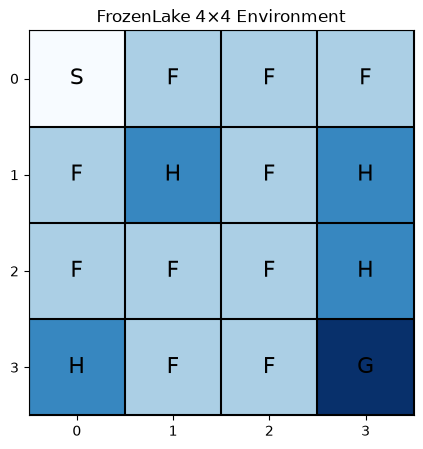

In [4]:
import numpy as np
import matplotlib.pyplot as plt

desc = env.unwrapped.desc.astype("U1")

# Map each tile to a numeric value for visualization
tile_values = {
    "S": 0,  # Start
    "F": 1,  # Frozen
    "H": 2,  # Hole
    "G": 3   # Goal
}

grid = np.array([
    [tile_values[tile] for tile in row]
    for row in desc
])

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(grid, cmap="Blues", vmin=0, vmax=3)

for row in range(4):
    for col in range(4):
        ax.text(
            col, row, desc[row, col],
            ha="center", va="center",
            fontsize=16, color="black"
        )

ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
ax.grid(which="minor", color="black", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_title("FrozenLake 4×4 Environment")
plt.show()

## State and Action Representation

### State representation

FrozenLake represents each grid position using an integer from 0 to 15. The mapping is row-major: states increase from left to right, then continue on the next row.

For a grid with 4 columns, the row and column corresponding to state (s) are:

$$
\mathrm{row} = \lfloor s / 4 \rfloor
$$

$$
\mathrm{column} = s \bmod 4
$$

For example, state (s=6) corresponds to row (1), column (2), using zero-based indexing.

### Action representation

The action space contains four discrete actions:

| Action | Direction |
|---:|---|
| 0 | Left |
| 1 | Down |
| 2 | Right |
| 3 | Up |

The agent observes its current state, selects an action, and receives the next state, reward, and episode termination information from the environment.

## 3. Interacting with the Environment

An RL agent interacts with FrozenLake through two main methods:

- `env.reset()` initializes an episode and returns the initial state.
- `env.step(action)` executes an action and returns the next state, reward, termination status, truncation status, and additional information.

This interaction loop is the foundation of reinforcement learning.

In [5]:
state, info = env.reset()
print("Initial state:", state)

action = 2  # Move right
next_state, reward, terminated, truncated, info = env.step(action)

print("Next state:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

Initial state: 0
Next state: 1
Reward: 0
Terminated: False
Truncated: False


## 4. Rewards and Episode Termination

FrozenLake uses a sparse reward structure:

- **Goal reached:** reward of \(+1\).
- **Frozen tile or hole:** reward of \(0\).

An episode ends when the agent reaches the goal, falls into a hole, or the episode is truncated by the time limit.

Because intermediate rewards are zero, the agent must learn which actions lead to eventual success rather than relying on immediate rewards alone.

This makes FrozenLake a useful environment for studying long-term reward optimization.